## 1. Extracting data from drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [8]:
#unzing the image folder
import zipfile

with zipfile.ZipFile("/content/drive/MyDrive/Amar_project_dataset/colabDataset.zip", "r") as zip_ref:
    # Extracts to a folder named 'extracted_files' (creates it if it doesn't exist)
    zip_ref.extractall("extracted_files")


## 2. Importing Libraries

In [9]:
import numpy as np  # Importing NumPy for numerical operations and array manipulations
import matplotlib.pyplot as plt  # Importing Matplotlib for plotting graphs and visualizations
import seaborn as sns  # Importing Seaborn for statistical data visualization, built on top of Matplotlib
import tensorflow as tf  # Importing TensorFlow for building and training machine learning models
from tensorflow import keras  # Importing Keras, a high-level API for TensorFlow, to simplify model building
from tensorflow.keras import Layer  # Importing Layer class for creating custom layers in Keras
from tensorflow.keras.models import Sequential  # Importing Sequential model for building neural networks layer-by-layer
from tensorflow.keras.layers import Rescaling , GlobalAveragePooling2D
from tensorflow.keras import layers, optimizers, callbacks  # Importing various modules for layers, optimizers, and callbacks in Keras
from sklearn.utils.class_weight import compute_class_weight  # Importing function to compute class weights for imbalanced datasets
from tensorflow.keras.applications import EfficientNetV2B2  # Importing EfficientNetV2S model for transfer learning
from sklearn.metrics import confusion_matrix, classification_report  # Importing functions to evaluate model performance

## 3. Loading Dataset

In [19]:
# Loading Dataset
dataset_dir= r"/content/extracted_files/TrashType_Image_Dataset"

image_size = (224, 224)
batch_size = 32
seed = 42

# Load training dataset
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    shuffle=True,
    image_size=image_size,
    batch_size=batch_size
)

# Load validation dataset
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    shuffle=True,
    image_size=image_size,
    batch_size=batch_size
)

# Get class names from validation dataset
val_class = val_ds.class_names

# Split validation into test and validation sets
val_batches = tf.data.experimental.cardinality(val_ds)
test_ds = val_ds.take(val_batches // 2)
val_dat = val_ds.skip(val_batches // 2)

# Optimize test dataset
test_ds_eval = test_ds.cache().prefetch(tf.data.AUTOTUNE)

# Pretty output section
print("\nDataset Summary")
print("-" * 30)

print("Class Names:")
for i, cls in enumerate(train_ds.class_names, 1):
    print(f"  {i}. {cls}")

print(f"\nTotal Classes     : {len(train_ds.class_names)}")
print(f"Training Batches  : {len(train_ds)}")
print(f"Validation Batches: {len(val_dat)}")
print(f"Test Batches      : {len(test_ds)}")
print("-" * 30)

Found 2526 files belonging to 6 classes.
Using 2021 files for training.
Found 2526 files belonging to 6 classes.
Using 505 files for validation.

Dataset Summary
------------------------------
Class Names:
  1. cardboard
  2. glass
  3. metal
  4. paper
  5. plastic
  6. trash

Total Classes     : 6
Training Batches  : 64
Validation Batches: 8
Test Batches      : 8
------------------------------


## 4. Visualizing the dataset

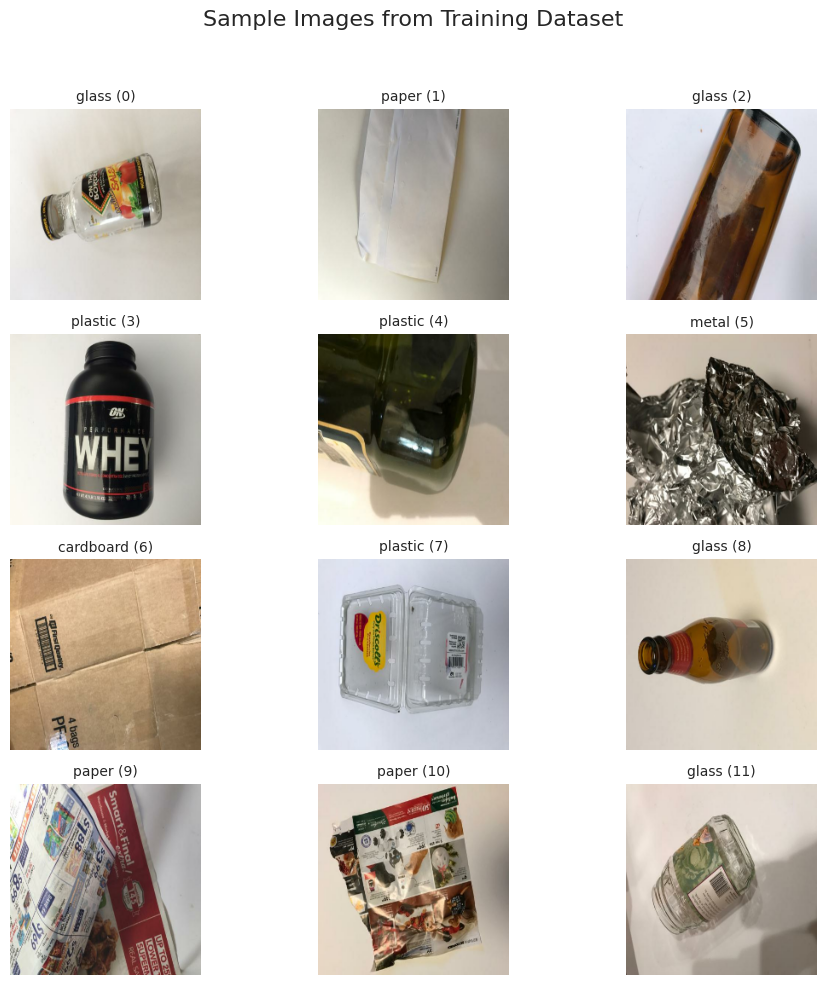

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))
for images, labels in train_ds.take(1):
    num_images = min(len(images), 12)
    for i in range(num_images):
        ax = plt.subplot(4, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(f"{train_ds.class_names[labels[i]]} ({i})", fontsize=10)
        plt.axis("off")

plt.suptitle("Sample Images from Training Dataset", fontsize=16)
plt.tight_layout(rect=[0, 0, 1, 0.95])  # adjust to make space for title
plt.show()

## 5. Checking Class distribution


Class Distribution Summary:

    Class  Train (%)  Validation (%)  Test (%)  Overall (%)
cardboard      16.53           13.66     11.72        15.10
    glass      19.74           20.20     19.14        19.97
    metal      15.93           17.43     20.70        16.68
    paper      23.31           24.36     25.78        23.84
  plastic      19.45           17.62     15.23        18.54
    trash       5.05            6.73      7.42         5.89


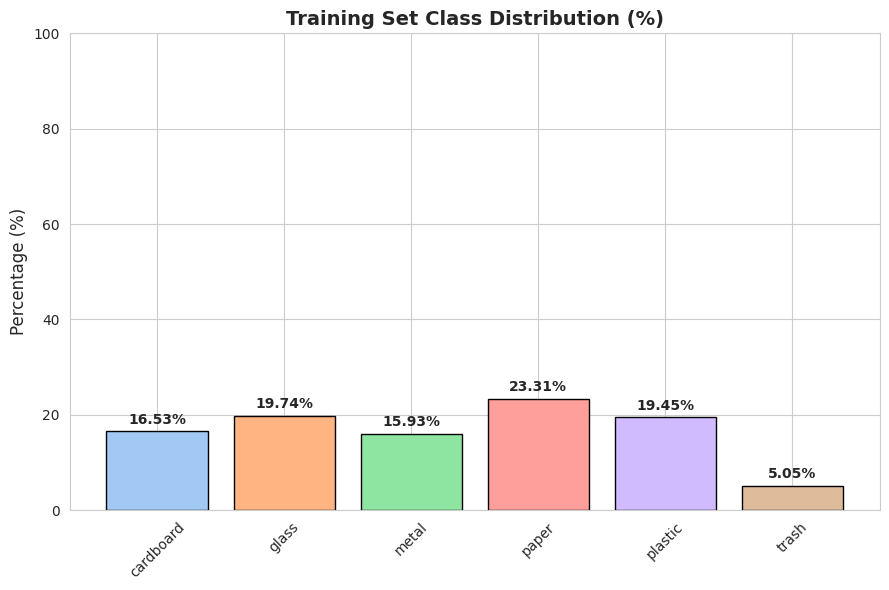

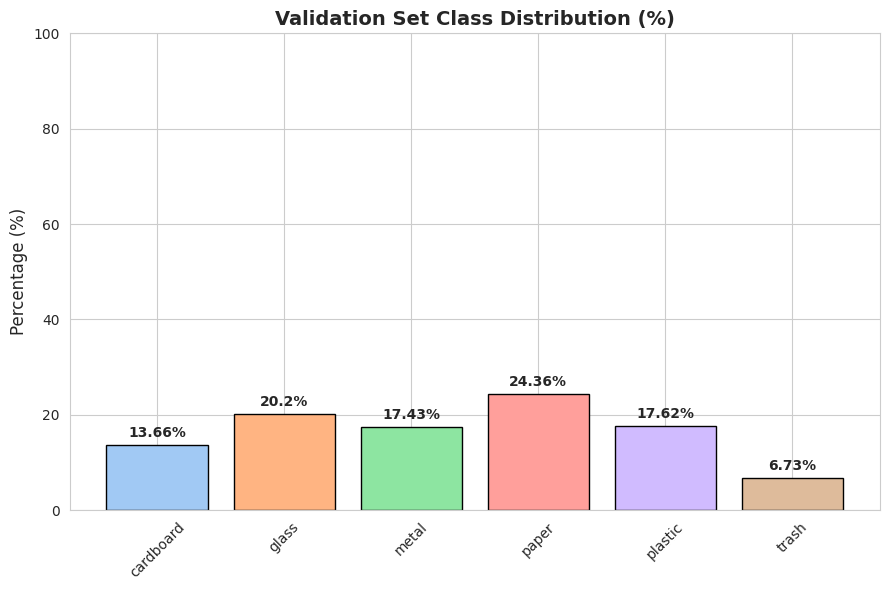

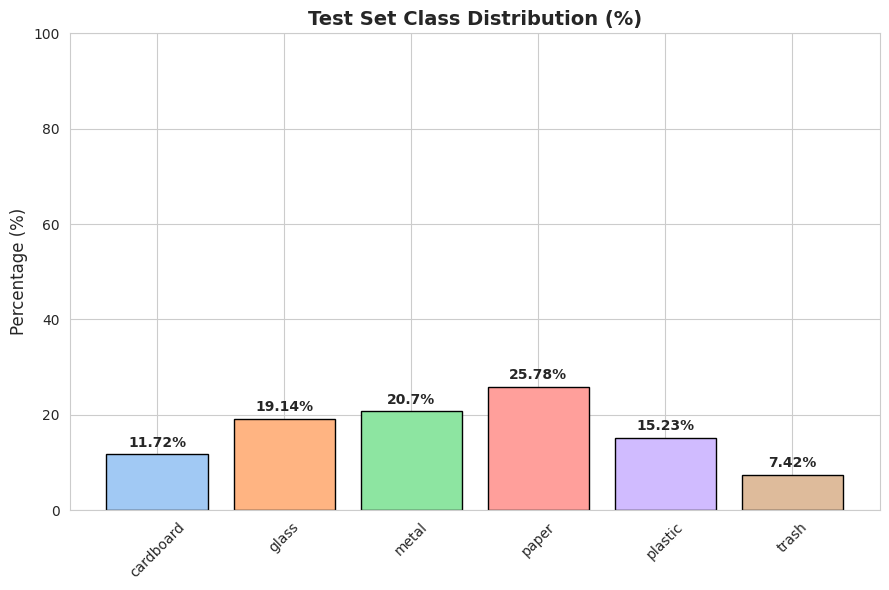

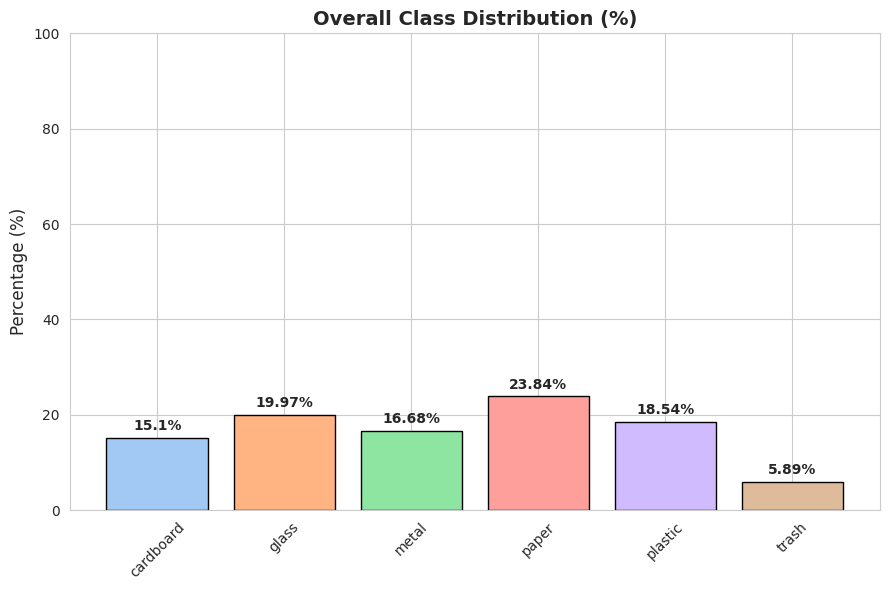

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

# Function to count class distribution (in %)
def count_distribution(dataset, class_names):
    total = 0
    counts = {name: 0 for name in class_names}

    for _, labels in dataset:
        for label in labels.numpy():
            counts[class_names[label]] += 1
            total += 1

    return {k: round((v / total) * 100, 2) for k, v in counts.items()}

# Improved bar plot function with seaborn
def simple_bar_plot(dist, title):
    plt.figure(figsize=(9, 6))
    sns.set_style("whitegrid")

    bars = plt.bar(dist.keys(), dist.values(), color=sns.color_palette("pastel"), edgecolor='black')

    # Add value labels on top
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, height + 1, f'{height}%',
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

    plt.title(title, fontsize=14, fontweight='bold')
    plt.ylabel('Percentage (%)', fontsize=12)
    plt.xticks(rotation=45, fontsize=10)
    plt.ylim(0, 100)
    plt.tight_layout()
    plt.show()

    # Get class names
class_names = train_ds.class_names

# Compute distributions
train_dist = count_distribution(train_ds, class_names)
val_dist = count_distribution(val_ds, class_names)
test_dist = count_distribution(test_ds, class_names)
overall_dist = {k: round((train_dist[k] + val_dist[k]) / 2, 2) for k in class_names}

# Create DataFrame
dist_df = pd.DataFrame({
    'Class': class_names,
    'Train (%)': [train_dist[k] for k in class_names],
    'Validation (%)': [val_dist[k] for k in class_names],
    'Test (%)': [test_dist[k] for k in class_names],
    'Overall (%)': [overall_dist[k] for k in class_names],
})

# Print clean table
print("\nClass Distribution Summary:\n")
print(dist_df.to_string(index=False))

# Plot distributions
simple_bar_plot(train_dist, "Training Set Class Distribution (%)")
simple_bar_plot(val_dist, "Validation Set Class Distribution (%)")
simple_bar_plot(test_dist, "Test Set Class Distribution (%)")
simple_bar_plot(overall_dist, "Overall Class Distribution (%)")

## 6. Calculating Class Weights to Handle Imbalance

In [21]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# Count class occurrences and collect all labels
class_counts = {i: 0 for i in range(len(class_names))}
all_labels = []

for images, labels in train_ds:
    for label in labels.numpy():
        class_counts[label] += 1
        all_labels.append(label)

# Compute class weights (balanced)
class_weights_array = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(class_names)),
    y=all_labels
)

# Map class index to weight
class_weights = {i: round(w, 4) for i, w in enumerate(class_weights_array)}

# ✨ Display results nicely
print("\n Class Distribution in Training Set")
print("-" * 40)
for i, name in enumerate(class_names):
    print(f"{i}. {name:<10} ➤ Samples: {class_counts[i]:<4} | Weight: {class_weights[i]}")
print("-" * 40)
print(f"\n Total Training Samples: {sum(class_counts.values())}")


 Class Distribution in Training Set
----------------------------------------
0. cardboard  ➤ Samples: 334  | Weight: 1.0085
1. glass      ➤ Samples: 399  | Weight: 0.8442
2. metal      ➤ Samples: 322  | Weight: 1.0461
3. paper      ➤ Samples: 471  | Weight: 0.7151
4. plastic    ➤ Samples: 393  | Weight: 0.8571
5. trash      ➤ Samples: 102  | Weight: 3.3023
----------------------------------------

 Total Training Samples: 2021


## 7. Preprocessing and Model Training


 Starting Model Training...
Epochs       : 10
Class Weights: {0: np.float64(1.0085), 1: np.float64(0.8442), 2: np.float64(1.0461), 3: np.float64(0.7151), 4: np.float64(0.8571), 5: np.float64(3.3023)}
Checkpoint   : Best model saved to 'best_model.keras'
Early Stop   : Enabled with patience=3



0epoch [00:00, ?epoch/s]

0batch [00:00, ?batch/s]

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.3606 - loss: 1.6228
Epoch 1: val_accuracy improved from None to 0.72475, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 530s 7s/step - accuracy: 0.4943 - loss: 1.4259 - val_accuracy: 0.7248 - val_loss: 0.9270
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.7427 - loss: 0.8704
Epoch 2: val_accuracy improved from 0.72475 to 0.82970, saving model to best_model.keras

Epoch 2: finished saving model to best_model.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 466s 7s/step - accuracy: 0.7605 - loss: 0.7825 - val_accuracy: 0.8297 - val_loss: 0.5487
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 0s 7s/step - accuracy: 0.8399 - loss: 0.5180
Epoch 3: val_accuracy improved from 0.82970 to 0.87525, saving model to best_model.keras

Epoch 3: finished saving model to best_model.keras
64/64 ━━━━━━━━━━━━━━━━━━━━ 501s 7s/step - accuracy: 0.8605 - loss: 0.4692 - val_accuracy: 0.8752 - 

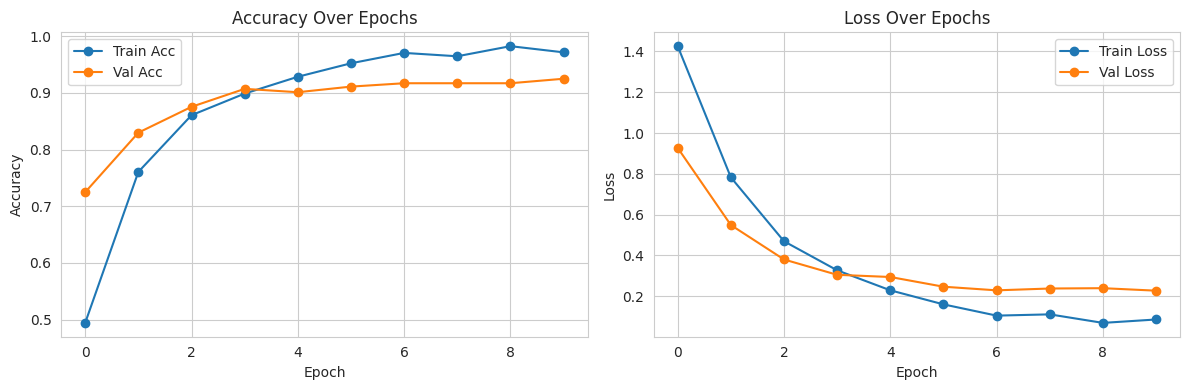

In [24]:

import pandas as pd
import matplotlib.pyplot as plt
from tqdm.keras import TqdmCallback
from tensorflow.keras.models import Sequential
from tensorflow.keras import layers, optimizers, callbacks
from tensorflow.keras.layers import GlobalAveragePooling2D
from tensorflow.keras.applications import EfficientNetV2B2
import tensorflow as tf
import pickle

# Data Augmentation
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
])

# Load Pretrained EfficientNetV2B2 with matching input size
base_model = EfficientNetV2B2(
    include_top=False,
    input_shape=(224, 224, 3),
    include_preprocessing=True,
    weights='imagenet'
)

# Freeze early layers
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False

# Build Final Model
model = Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    base_model,
    GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(6, activation='softmax')
])
# Compile Model
model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Callbacks
early = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = callbacks.ModelCheckpoint(
    filepath='best_model.keras',
    monitor='val_accuracy',
    save_best_only=True,
    mode='max',
    verbose=1
)

# Pre-training Summary
epochs = 10
print("\n Starting Model Training...")
print(f"Epochs       : {epochs}")
print(f"Class Weights: {class_weights}")
print(f"Checkpoint   : Best model saved to 'best_model.keras'")
print(f"Early Stop   : Enabled with patience=3\n")

# Train the Model with Tqdm progress bar
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,
    class_weight=class_weights,
    batch_size=32,
    callbacks=[early, checkpoint, TqdmCallback(verbose=1)]
)

# Display training log as a table
df_log = pd.DataFrame(history.history)
print("\n Training Log Summary:")
print(df_log.to_string(index=True))

# Save history for later comparison
with open("history.pkl", "wb") as f:
    pickle.dump(history.history, f)

# Plot Accuracy and Loss Graphs
plt.figure(figsize=(12, 4))

# Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Acc', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Acc', marker='o')
plt.title('Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

# Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## 8. Model evaluation


Loading Model: best_model.keras

Evaluating Model on Test Dataset...
--------------------------------------------------
 Test Accuracy : 0.9414
 Test Loss     : 0.1829
--------------------------------------------------

 Classification Report:
--------------------------------------------------
              precision    recall  f1-score   support

   cardboard       1.00      0.84      0.92        32
       glass       0.98      0.88      0.93        60
       metal       0.91      1.00      0.95        40
       paper       0.91      1.00      0.95        61
     plastic       0.94      0.96      0.95        46
       trash       0.94      0.94      0.94        17

    accuracy                           0.94       256
   macro avg       0.95      0.94      0.94       256
weighted avg       0.94      0.94      0.94       256

--------------------------------------------------


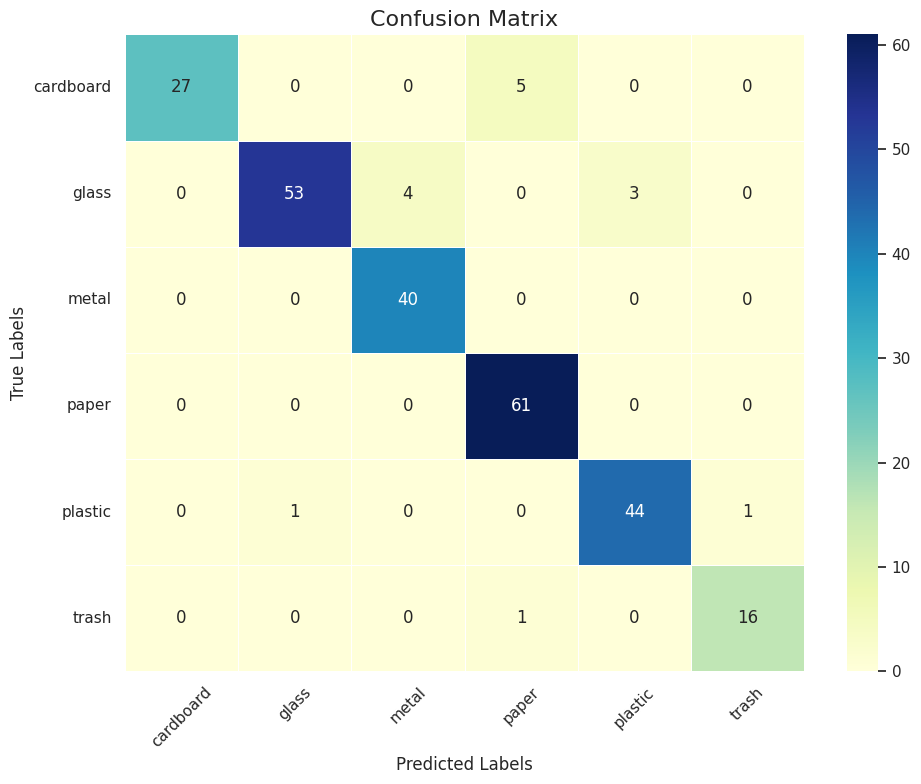

In [27]:
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import tensorflow as tf


def evaluate_model(model_path, test_dataset, class_names):
    # Load the model
    print(f"\nLoading Model: {model_path}")
    model = tf.keras.models.load_model(model_path)

    # Evaluate on test set
    print("\nEvaluating Model on Test Dataset...\n" + "-"*50)
    loss, accuracy = model.evaluate(test_dataset, verbose=0)
    print(f" Test Accuracy : {accuracy:.4f}")
    print(f" Test Loss     : {loss:.4f}")
    print("-"*50)

    # True and predicted labels
    y_true = np.concatenate([labels.numpy() for _, labels in test_dataset])
    y_pred_probs = model.predict(test_dataset, verbose=0)
    y_pred = np.argmax(y_pred_probs, axis=1)

    # Classification Report
    print("\n Classification Report:\n" + "-"*50)
    report = classification_report(y_true, y_pred, target_names=class_names)
    print(report)
    print("-"*50)

    # Confusion Matrix
    cm = confusion_matrix(y_true, y_pred)

    # Plot Confusion Matrix
    plt.figure(figsize=(10, 8))
    sns.set(style="whitegrid")
    sns.heatmap(cm, annot=True, fmt="d", cmap="YlGnBu", linewidths=.5,
                xticklabels=class_names, yticklabels=class_names)


    plt.title("Confusion Matrix", fontsize=16)
    plt.xlabel("Predicted Labels", fontsize=12)
    plt.ylabel("True Labels", fontsize=12)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

# 🧪 Example usage
evaluate_model("best_model.keras", test_ds_eval, class_names)

## 9. Checking model accuracy on test data

1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


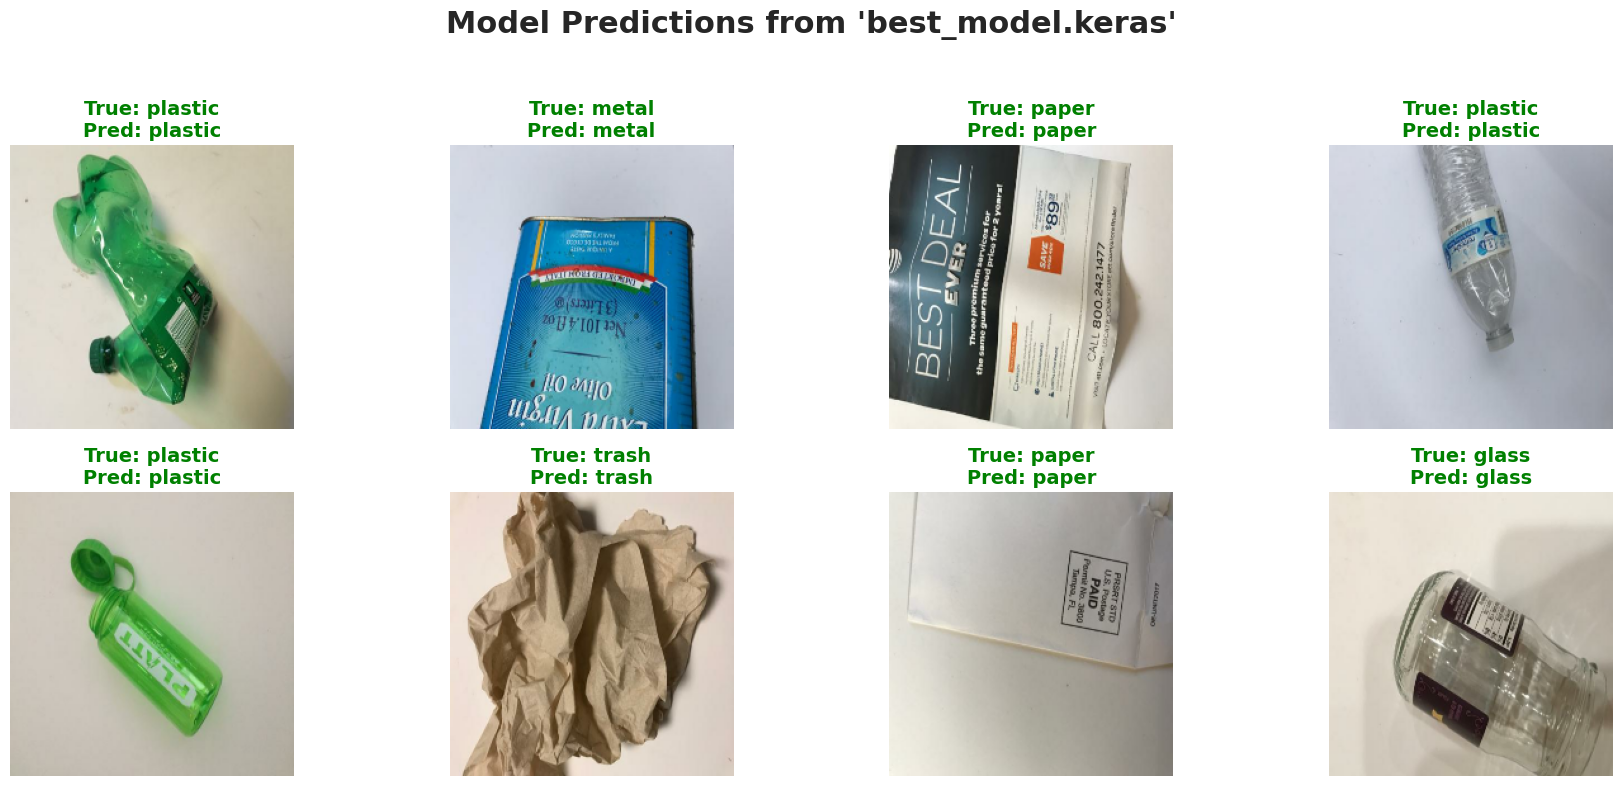

In [28]:
import matplotlib.pyplot as plt
import tensorflow as tf

# Load your trained model
model_path = 'best_model.keras'  # Change if needed
model = tf.keras.models.load_model(model_path)

# Get class names from training dataset
class_names = train_ds.class_names

# Shuffle test dataset before sampling
test_ds_eval_shuffled = test_ds_eval.shuffle(1000, reshuffle_each_iteration=True)

# Take one random batch from test dataset and predict
for images, labels in test_ds_eval_shuffled.take(1):
    predictions = model.predict(images)
    pred_labels = tf.argmax(predictions, axis=1)

    # Plot first 8 images with predictions
    plt.figure(figsize=(18, 8))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        true_cls = class_names[labels[i]]
        pred_cls = class_names[pred_labels[i]]

        # Green if correct, red if wrong
        title_color = 'green' if true_cls == pred_cls else 'red'
        plt.title(f"True: {true_cls}\nPred: {pred_cls}", color=title_color, fontsize=14, fontweight='bold')  # ← increased font size here
        plt.axis("off")

    plt.suptitle(f"Model Predictions from '{model_path}'", fontsize=22, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    plt.show()

## 10. Evaluating model metrics

In [29]:
import tensorflow as tf
import pickle
import pandas as pd

# === Paths ===
model_path = 'best_model.keras'
history_path = 'history.pkl'

# === Load the model ===
model = tf.keras.models.load_model(model_path)
print(f"Loaded model from: {model_path}")


# === Load history ===
with open(history_path, 'rb') as f:
    history = pickle.load(f)

# === Get final epoch metrics ===
final_accuracy     = history['accuracy'][-1]
final_val_accuracy = history['val_accuracy'][-1]
final_loss         = history['loss'][-1]
final_val_loss     = history['val_loss'][-1]

print("\n Final Training Summary:")
print(f"Train Accuracy     : {final_accuracy:.4f}")
print(f"Validation Accuracy: {final_val_accuracy:.4f}")
print(f"Train Loss         : {final_loss:.4f}")
print(f"Validation Loss    : {final_val_loss:.4f}")

Loaded model from: best_model.keras

 Final Training Summary:
Train Accuracy     : 0.9713
Validation Accuracy: 0.9248
Train Loss         : 0.0856
Validation Loss    : 0.2269
